# Lab 4 · One orbit for everything: transit, velocities and timing

Each kind of data constrains something different. The transit gives the planet's size and the inclination; the
velocities give the mass and the shape of the orbit; transit and eclipse times spread over fifteen years pin the
period. A **joint fit** asks one orbit to explain all of them at once, which is how published parameters are made.
This is the analysis of Pearson et al. (2022) for HD 80606 b, as the website's worked example stores it.

In [1]:
import os
import urllib.request
import esl
import esl.plot

DATA = os.environ.get("ESL_DATA", "https://pearsonkyle.github.io/Exoplanet-Science-Lab/examples/")
fetch = lambda path: urllib.request.urlopen(DATA + path).read().decode()

## 1. Open the worked example

The session holds the TESS light curve, 264 velocities from seven instruments, four transit times and one eclipse
time, and the priors. **Kepler's law ties a/R★** to the period and the star's mass and radius, so the light curve
and the velocities share one orbit (a/R★ is never sampled on its own: it is degenerate with the inclination).

In [2]:
session = esl.Session.model_validate_json(fetch("results/hd80606-joint.json"))
print(session.summary())

HD 80606
  planets: b  (a/R* from Kepler's law)
  light curve: 899 points
  velocities ELODIE: 74 points
  velocities HIRES_k: 39 points
  velocities HRS_1: 7 points
  velocities HRS_2: 16 points
  velocities HIRES_j: 75 points
  velocities SOPHIE: 48 points
  velocities APF: 5 points
  timing: 5 mid-times
  limb darkening: nonlinear, fixed or sampled coefficients
  free (7): rprs ~ Uniform(0.01, 0.2), inc ~ Uniform(87, 90), per ~ Uniform(111.43633, 111.43717), tmid ~ Uniform(2458887.876, 2458888.276), ecc ~ Uniform(0.93096, 0.93216), omega ~ Uniform(-59.04, -58.62), mplanet ~ Uniform(4.172, 4.202)
  sampler: 400 live points, seed 42


## 2. Fit it again

The stored file already has a result (from the website). Running it here samples everything again, in about a
minute: twelve free parameters.

In [3]:
fit = session.run()
print(fit.result.table())

converged: 57440 calls, 12.9 s, ln Z = 3359.936 +- 0.217, chi2 = 1675.14 for 1168 measurements
  rprs       0.0725 +0.0012 -0.0013
  inc        89.2412 +0.0086 -0.0078  °
  per        111.436866 +0.000065 -0.000063  d
  tmid       2458888.0711 +0.0021 -0.0019  d
  ecc        0.93160 +0.00011 -0.00011
  omega      -58.823 +0.033 -0.033  °
  mplanet    4.1883 +0.0030 -0.0031  M Jup
  derived:
  rpJup      0.741 +0.012 -0.013
  t14        0.4697 +0.0061 -0.0060
  emid       2458882.2109 +0.0026 -0.0024
  ars        94.452698 +0.000097 -0.000095
  b          0.8146 +0.0080 -0.0092
  K          469.86 +0.35 -0.42


## 3. Each dataset against the one model

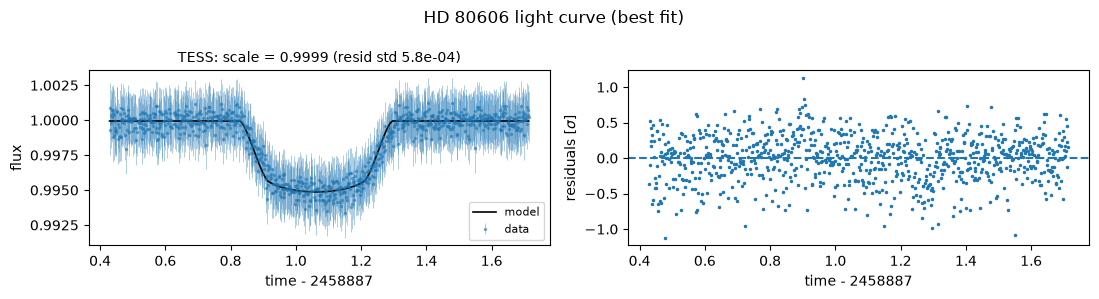

In [4]:
esl.plot.light_curve(fit);

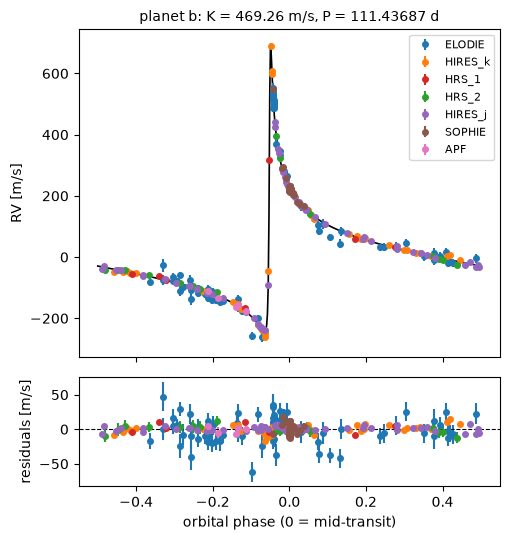

In [5]:
esl.plot.radial_velocity(fit, fold=True);

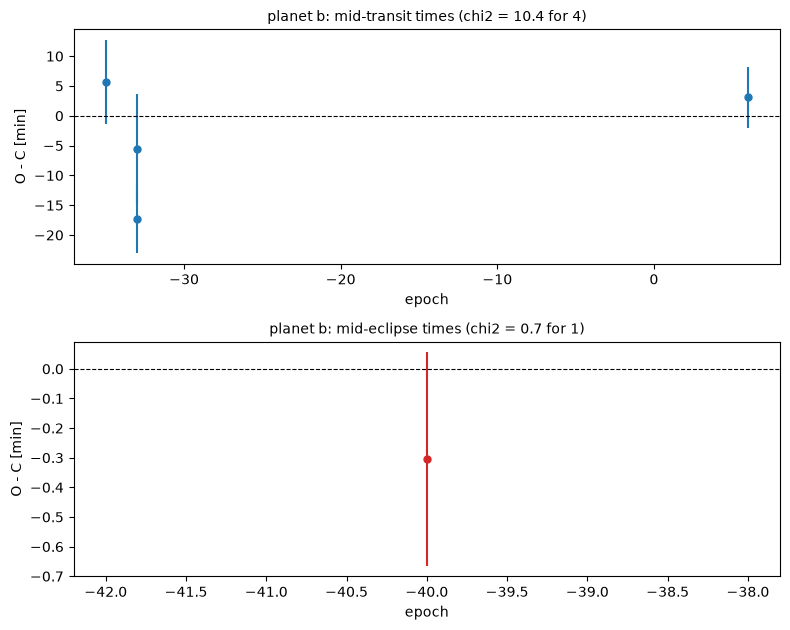

In [6]:
esl.plot.oc(fit);

## 4. Compare with the paper

Pearson et al. (2022) report P = 111.4367 d, e = 0.93183 and ω = −58.887°. Differences of a couple of σ are
expected: the paper's fit had more data and treated the stellar parameters and jitters slightly differently. The
planet's mass also scales with the star's mass assumed (as M★^(2/3)), so compare it with care.

In [7]:
paper = dict(per=111.4367, ecc=0.93183, omega=-58.887)
for key, ref in paper.items():
    q = fit.result[key] if key in fit.result else fit.result.derived[key]
    print(f"{key:8s} {q.median:.6g} +{q.plus:.2g} -{q.minus:.2g}   paper {ref}   ({(q.median - ref) / max(q.plus, q.minus, 1e-12):+.1f} sigma)")

per      111.437 +6.5e-05 -6.3e-05   paper 111.4367   (+2.6 sigma)
ecc      0.931596 +0.00011 -0.00011   paper 0.93183   (-2.1 sigma)
omega    -58.8226 +0.033 -0.033   paper -58.887   (+1.9 sigma)


**Next:** [Lab 5](./lab05_ephemeris) works with transit times alone.